**LIBRERÍAS**

In [ ]:
#!/usr/bin/python

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Softmax

**OBTENCIÓN DE DATOS**

In [6]:
from keras.datasets import cifar10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
class_names = ['aeroplano', 'autómovil', 'pájaro', 'gato', 'ciervo',
               'perro', 'rana', 'caballo', 'yate', 'camión']

170508288/170498071 [==============================] - 2s 0us/step


In [8]:
y_train[1]

array([9], dtype=uint8)

**PREPROCESAMIENTO DE DATOS**

In [ ]:
# El valore de los pixeles está entre 0 a 255.
# Normalizamos entonces entre 0 y 1.
X_train, X_test = X_train / 255.0, X_test / 255.0

In [ ]:
print('Tamaño de los datos de entrenamiento:     ', X_train.shape)
print('Tamaño de las etiquetas de entrenamiento: ', y_train.shape)
print('Tamaño de los datos de prueba:            ', X_test.shape)
print('Tamaño de las etiquetas de prueba:        ', y_test.shape)

Tamaño de los datos de entrenamiento:      (50000, 32, 32, 3)
Tamaño de las etiquetas de entrenamiento:  (50000, 1)
Tamaño de los datos de prueba:             (10000, 32, 32, 3)
Tamaño de las etiquetas de prueba:         (10000, 1)


La característica de los datos -.
Salida:  7  --  caballo


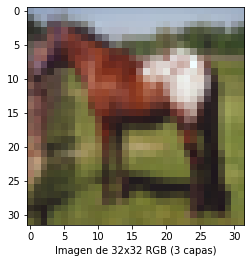

In [ ]:
print('La característica de los datos -.')
i = 1900
plt.figure()
plt.imshow(X_train[i], cmap=plt.cm.binary)
plt.xlabel('Imagen de 32x32 RGB (3 capas)')
print('Salida: ', y_train[i,:][0], ' -- ', class_names[y_train[i][0]])

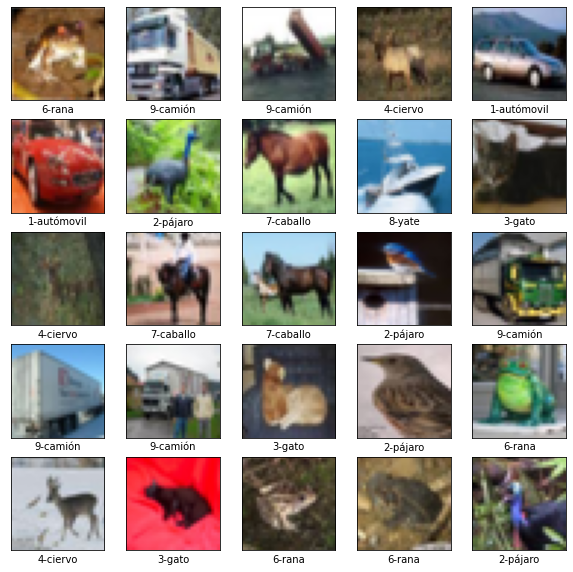

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    # The CIFAR labels happen to be arrays, 
    # which is why you need the extra index
    plt.xlabel(str(y_train[i][0])+'-'+class_names[y_train[i][0]])
plt.show()

In [ ]:
import numpy as np
nr = np.floor((32-3+2*0)/1)+1
print(nr)

30.0


**GENERACIÓN DEL MODELO**

In [ ]:
model = Sequential()


model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))

model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))

model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))

model.add(Flatten())

model.add(Dense(64, activation='relu'))
model.add(Dense(10))

model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 30, 30, 32)        896       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 15, 15, 32)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 13, 13, 64)        18496     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 6, 6, 64)          0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 4, 4, 64)          36928     
_________________________________________________________________
flatten (Flatten)            (None, 1024)              0         
_________________________________________________________________
dense (Dense)                (None, 64)                6

**COMPILAMOS Y ENTRENAMOS EL MODELO**

In [ ]:
import tensorflow as tf

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

- No usar la CPU para entrenar, cambiar a GPU o TPU. (Runtime - Change runtime type - Seleccionar GPU o TPU)

Epoch 1/10
1407/1407 [==============================] - 40s 7ms/step - loss: 1.8135 - accuracy: 0.3275 - val_loss: 1.3555 - val_accuracy: 0.5162
Epoch 2/10
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2112 - accuracy: 0.5685 - val_loss: 1.1347 - val_accuracy: 0.5878
Epoch 3/10
1407/1407 [==============================] - 10s 7ms/step - loss: 1.0318 - accuracy: 0.6355 - val_loss: 0.9810 - val_accuracy: 0.6504
Epoch 4/10
1407/1407 [==============================] - 10s 7ms/step - loss: 0.9150 - accuracy: 0.6784 - val_loss: 0.8907 - val_accuracy: 0.6898
Epoch 5/10
1407/1407 [==============================] - 10s 7ms/step - loss: 0.8332 - accuracy: 0.7065 - val_loss: 0.8422 - val_accuracy: 0.7076
Epoch 6/10
1407/1407 [==============================] - 10s 7ms/step - loss: 0.7676 - accuracy: 0.7315 - val_loss: 0.8323 - val_accuracy: 0.7108
Epoch 7/10
1407/1407 [==============================] - 10s 7ms/step - loss: 0.7102 - accuracy: 0.7524 - val_loss: 0.8199 - val_ac

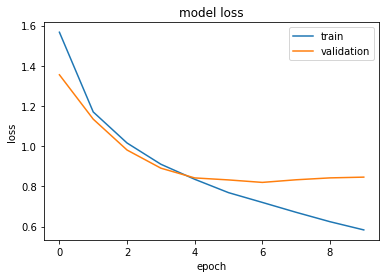

In [ ]:
history = model.fit(X_train, y_train, epochs=10, verbose=1, validation_split=0.1)
model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

**EVALUACIÓN DEL MODELO**

313/313 - 1s - loss: 0.8883 - accuracy: 0.7118


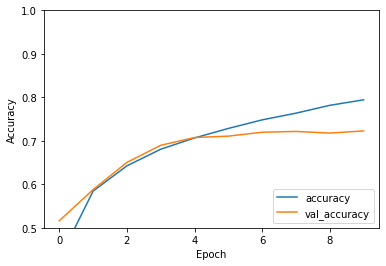

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)

In [ ]:
print('test_acc:  ', test_acc*100)
print('test_loss: ', test_loss)

test_acc:   71.17999792098999
test_loss:  0.8883233666419983


**PREDICCIÓN**


In [ ]:
select_imag = 8054
print(X_test[select_imag].shape)
print(model.predict(X_test[select_imag]))

(32, 32, 3)


ValueError: ignored

In [ ]:
print(model.input_shape)
print(len(model.input_shape))

(None, 32, 32, 3)
4


In [ ]:
#test = X_test[select_imag].reshape( (1,) + X_test[0].shape )
#test = X_test[np.newaxis, :, :, :]
test = np.expand_dims(X_test,axis=0)
print(x_prueba.shape)

(1, 32, 32, 3)


In [ ]:
prediccion = model.predict(x_prueba)
print(prediccion)

[[-7.2250323  -6.159854    0.16612194  1.3763733  -3.1618505   6.3723702
  -2.369101    0.42524183 -4.77001    -3.4064233 ]]


In [ ]:
softmax = tf.keras.layers.Softmax()
print(softmax(prediccion).numpy())

[[1.2293342e-06 3.5667349e-06 1.9934599e-03 6.6867168e-03 7.1496936e-05
  9.8843211e-01 1.5796981e-04 2.5831037e-03 1.4317685e-05 5.5984896e-05]]


In [ ]:
print(np.argmax(softmax(prediccion).numpy()))

5


In [ ]:
prediccion = np.argmax(softmax(model.predict(x_prueba)).numpy())

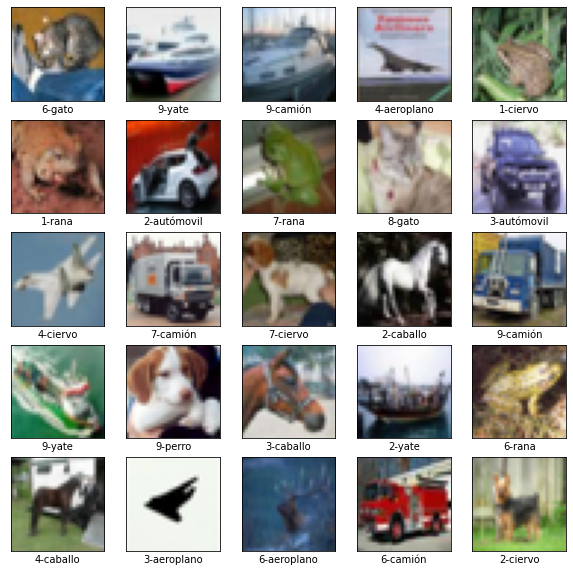

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_test[i], cmap=plt.cm.binary)
    test = X_test[i].reshape( (1,) + X_test[0].shape )
    prediccion = model.predict(test)
    prediccion = np.argmax(softmax(prediccion).numpy())
    # The CIFAR labels happen to be arrays, 
    # which is why you need the extra index
    plt.xlabel(str(y_train[i][0])+'-'+class_names[prediccion])
plt.show()

**Referencias**

*   https://www.tensorflow.org/tutorials/images/cnn 
*   https://keras.io/api/layers/activation_layers/softmax/